# Twitter US Airline Sentiment Analysis using Bidirectional LSTM
### *Mostafa Tamer*

In [3]:
# ==============================
# Data Handling
# ==============================
import os
import re
import string
import random
import numpy as np
import pandas as pd

# ==============================
# Visualization
# ==============================
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================
# Machine Learning
# ==============================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer
)

# ==============================
# TensorFlow
# ==============================
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, GRU, Dense, Dropout, SpatialDropout1D
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, Callback

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## 1. Load the Dataset

Download `Tweets.csv` from the Kaggle dataset and add it to your notebook environment. The path below matches the usual Kaggle input folder. If needed, change `DATA_PATH` to the location of your CSV.

In [2]:
DATA_PATH = "/kaggle/input/datasets/crowdflower/twitter-airline-sentiment/Tweets.csv"

df = pd.read_csv(DATA_PATH)
df.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [4]:
df.tail()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
14635,569587686496825344,positive,0.3487,NaN,0.0000,American,NaN,KristenReenders,NaN,0,@AmericanAir thank you we got on a different f...,NaN,2015-02-22 12:01:01 -0800,NaN,NaN
14636,569587371693355008,negative,1.0000,Customer Service Issue,1.0000,American,NaN,itsropes,NaN,0,@AmericanAir leaving over 20 minutes Late Flig...,NaN,2015-02-22 11:59:46 -0800,Texas,NaN
14637,569587242672398336,neutral,1.0000,NaN,NaN,American,NaN,sanyabun,NaN,0,@AmericanAir Please bring American Airlines to...,NaN,2015-02-22 11:59:15 -0800,"Nigeria,lagos",NaN
14638,569587188687634433,negative,1.0000,Customer Service Issue,0.6659,American,NaN,SraJackson,NaN,0,"@AmericanAir you have my money, you change my ...",NaN,2015-02-22 11:59:02 -0800,New Jersey,Eastern Time (US & Canada)
14639,569587140490866689,neutral,0.6771,NaN,0.0000,American,NaN,daviddtwu,NaN,0,@AmericanAir we have 8 ppl so we need 2 know h...,NaN,2015-02-22 11:58:51 -0800,"dallas, TX",NaN


In [5]:
df.shape

(14640, 15)

In [6]:
df.columns

Index(['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence',
       'negativereason', 'negativereason_confidence', 'airline',
       'airline_sentiment_gold', 'name', 'negativereason_gold',
       'retweet_count', 'text', 'tweet_coord', 'tweet_created',
       'tweet_location', 'user_timezone'],
      dtype='object')

In [7]:
df.isnull().sum()

tweet_id                            0
airline_sentiment                   0
airline_sentiment_confidence        0
negativereason                   5462
negativereason_confidence        4118
airline                             0
airline_sentiment_gold          14600
name                                0
negativereason_gold             14608
retweet_count                       0
text                                0
tweet_coord                     13621
tweet_created                       0
tweet_location                   4733
user_timezone                    4820
dtype: int64

In [ ]:
df.duplicated().sum()

In [8]:

df = df[["text", "airline_sentiment"]].dropna().copy()
df["text"] = df["text"].astype(str)
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (14452, 2)


,text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,positive
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative


## 2. Explore the Dataset

In [9]:
df["airline_sentiment"].value_counts()

airline_sentiment
negative    9087
neutral     3067
positive    2298
Name: count, dtype: int64

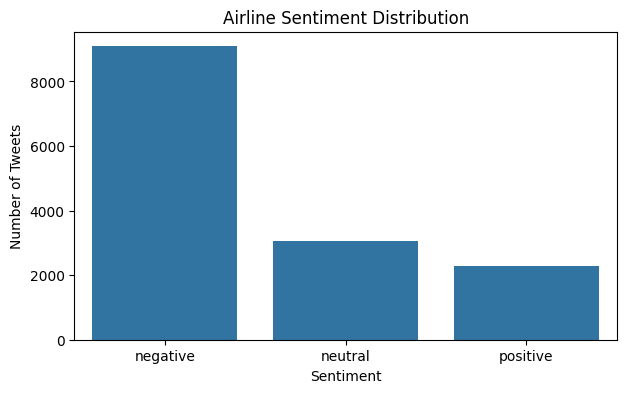

In [10]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="airline_sentiment", order=["negative", "neutral", "positive"])
plt.title("Airline Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.show()

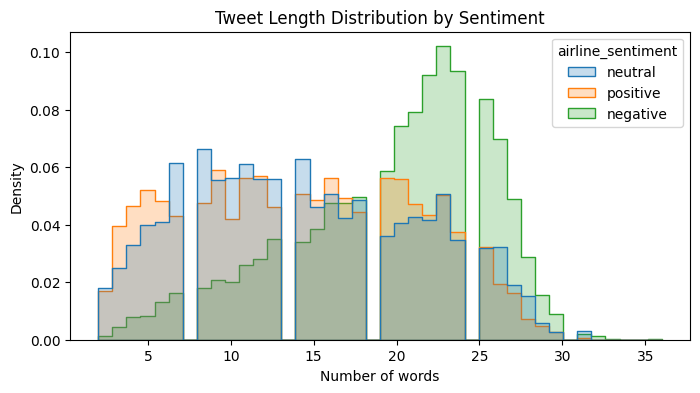

,count,mean,std,min,25%,50%,75%,max
airline_sentiment,,,,,,,,
negative,9087.0,19.690547,5.947176,2.0,16.0,21.0,24.0,36.0
neutral,3067.0,14.440822,6.946962,2.0,9.0,14.0,20.0,31.0
positive,2298.0,14.248042,6.919294,2.0,9.0,14.0,20.0,31.0


In [11]:
df["tweet_length"] = df["text"].str.split().str.len()
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="tweet_length", hue="airline_sentiment", bins=40, element="step", stat="density", common_norm=False)
plt.title("Tweet Length Distribution by Sentiment")
plt.xlabel("Number of words")
plt.show()

df.groupby("airline_sentiment")["tweet_length"].describe()

In [12]:
df[["text", "airline_sentiment"]].sample(5, random_state=SEED)

,text,airline_sentiment
3146,@united Surprised to go from 1K last year to n...,neutral
14086,"@AmericanAir @sa_craig no, not helped one bit....",negative
13469,@AmericanAir yes we did make it home. But by n...,negative
6942,“@JetBlue: Our fleet's on fleek. http://t.co/g...,positive
13008,@AmericanAir Thanks! Great stuff! I can only i...,positive


## 3. Split the Data Before Preprocessing

Reserve 20% as the final held-out test set using stratification. The test set will not be used for tokenizer fitting, model training, early stopping, or model selection.

In [13]:
X = df["text"].copy()
y = df["airline_sentiment"].copy()

X_train_all, X_test, y_train_all, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_all,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_all
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Held-out test:", X_test.shape, y_test.shape)

Training: (9248,) (9248,)
Validation: (2313,) (2313,)
Held-out test: (2891,) (2891,)


In [14]:
print("Training label distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\nValidation label distribution:")
print(y_val.value_counts(normalize=True).round(3))

Training label distribution:
airline_sentiment
negative    0.629
neutral     0.212
positive    0.159
Name: proportion, dtype: float64

Validation label distribution:
airline_sentiment
negative    0.629
neutral     0.212
positive    0.159
Name: proportion, dtype: float64


## 4. Clean and Prepare Tweets

In [15]:
def clean_tweet(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " URL ", text)
    text = re.sub(r"@\w+", " USER ", text)
    
    text = re.sub(r"#(\w+)", r" \1 ", text)
    
    text = text.replace("&amp;", " and ")
    text = re.sub(r"[^a-z0-9'!?.,$ ]+", " ", text)
    text = re.sub(r"([!?])\1+", r" \1 ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

print("Original tweet:")
print(X_train.iloc[0])
print("\n" + "=" * 90)
print("Cleaned tweet:")
print(clean_tweet(X_train.iloc[0]))

Original tweet:
@united says @USAirways  is the final carrier . Us air doesnt have it. I want my bag!!! Not a claim not an im  sorry. I want my clothes!!

Cleaned tweet:
says is the final carrier . us air doesnt have it. i want my bag ! not a claim not an im sorry. i want my clothes !


In [16]:
X_train_clean = X_train.apply(clean_tweet)
X_val_clean = X_val.apply(clean_tweet)
X_test_clean = X_test.apply(clean_tweet)

print(X_train_clean.head())

2280     says is the final carrier . us air doesnt have...
14258    cannot talk to any agents keep getting hung up...
9356     delays due to refueling are out of your contro...
6881     . navigating through 2 rebooks due to flu and ...
432      kinda sucked my earphone jack didn't work on m...
Name: text, dtype: object


## 5. Encode Labels

In [17]:
label_order = ["negative", "neutral", "positive"]
label_to_id = {label: idx for idx, label in enumerate(label_order)}
id_to_label = {idx: label for label, idx in label_to_id.items()}

y_train_enc = y_train.map(label_to_id).to_numpy()
y_val_enc = y_val.map(label_to_id).to_numpy()
y_test_enc = y_test.map(label_to_id).to_numpy()

print("Label mapping:", label_to_id)

Label mapping: {'negative': 0, 'neutral': 1, 'positive': 2}


## 6. Tokenize and Pad Sequences

In [18]:
VOCAB_SIZE = 20000
MAX_LENGTH = 50

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_clean)

X_train_seq = tokenizer.texts_to_sequences(X_train_clean)
X_val_seq = tokenizer.texts_to_sequences(X_val_clean)
X_test_seq = tokenizer.texts_to_sequences(X_test_clean)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LENGTH, padding="post", truncating="post")
X_val_pad = pad_sequences(X_val_seq, maxlen=MAX_LENGTH, padding="post", truncating="post")
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LENGTH, padding="post", truncating="post")

print("Vocabulary size used:", min(VOCAB_SIZE, len(tokenizer.word_index) + 1))
print("Train shape:", X_train_pad.shape)
print("Validation shape:", X_val_pad.shape)
print("Test shape:", X_test_pad.shape)

Vocabulary size used: 10547
Train shape: (9248, 50)
Validation shape: (2313, 50)
Test shape: (2891, 50)


In [19]:
print(X_train_clean.iloc[0])

says is the final carrier . us air doesnt have it. i want my bag ! not a claim not an im sorry. i want my clothes !


In [20]:
print(X_train_seq[0])

[245, 12, 3, 1201, 1580, 55, 269, 1581, 18, 15, 4, 146, 11, 79, 20, 5, 374, 20, 35, 543, 306, 4, 146, 11, 719]


In [21]:
print(X_train_pad[0])

[ 245   12    3 1201 1580   55  269 1581   18   15    4  146   11   79
   20    5  374   20   35  543  306    4  146   11  719    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0]


## 7. Handle Class Imbalance

Class weights are calculated from the training labels only. This can help the model pay more attention to underrepresented sentiment classes.

In [22]:
classes = np.unique(y_train_enc)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train_enc)
class_weight = {int(cls): float(weight) for cls, weight in zip(classes, weights)}
print("Class weights:", class_weight)

Class weights: {0: 0.5301232444826598, 1: 1.5703854644251996, 2: 2.097052154195011}


## 8. Build the Bidirectional LSTM Model

This is a three-class classifier, so the output layer uses `softmax` and the loss is `sparse_categorical_crossentropy`.

In [23]:
model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=128, input_length=MAX_LENGTH, mask_zero=False),
    SpatialDropout1D(0.25),
    Bidirectional(LSTM(64, dropout=0.2, recurrent_dropout=0.0)),
    Dense(64, activation="relu"),
    Dropout(0.4),
    Dense(3, activation="softmax")
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
I0000 00:00:1792609233.876996      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792609233.880722      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 9. Train with Validation Macro F1

Early stopping monitors validation Macro F1 rather than test performance. The held-out test set remains unused until the final evaluation cell.

In [24]:
class ValidationMacroF1(Callback):
    def __init__(self, val_data):
        super().__init__()
        self.X_val, self.y_val = val_data
        self.best_f1 = -1.0
        self.best_weights = None

    def on_epoch_end(self, epoch, logs=None):
        probs = self.model.predict(self.X_val, verbose=0)
        preds = np.argmax(probs, axis=1)
        score = f1_score(self.y_val, preds, average="macro")
        logs = logs or {}
        logs["val_macro_f1"] = score
        print(f" — val_macro_f1: {score:.4f}")
        if score > self.best_f1:
            self.best_f1 = score
            self.best_weights = self.model.get_weights()

In [25]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

macro_f1_callback = ValidationMacroF1((X_val_pad, y_val_enc))
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train_pad,
    y_train_enc,
    validation_data=(X_val_pad, y_val_enc),
    epochs=15,
    batch_size=64,
    class_weight=class_weight,
    callbacks=[macro_f1_callback, early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/15
143/145 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5459 - loss: 1.0114 — val_macro_f1: 0.6842
145/145 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.6162 - loss: 0.9173 - val_accuracy: 0.7549 - val_loss: 0.6187 - val_macro_f1: 0.6842 - learning_rate: 0.0010
Epoch 2/15
140/145 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7544 - loss: 0.6557 — val_macro_f1: 0.7072
145/145 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.7769 - loss: 0.6025 - val_accuracy: 0.7441 - val_loss: 0.6272 - val_macro_f1: 0.7072 - learning_rate: 0.0010
Epoch 3/15
142/145 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8368 - loss: 0.4525 — val_macro_f1: 0.7141

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
145/145 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.8454 - loss: 0.4320 - val_accuracy: 0.7562 - val_loss: 0.6282 - val_macro_f1: 0.7141 - learning_rate: 0.0010
Epoch 4/15
143/145 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8823 - loss: 0.3164 — val_macr

## 10. Inspect Training Curves

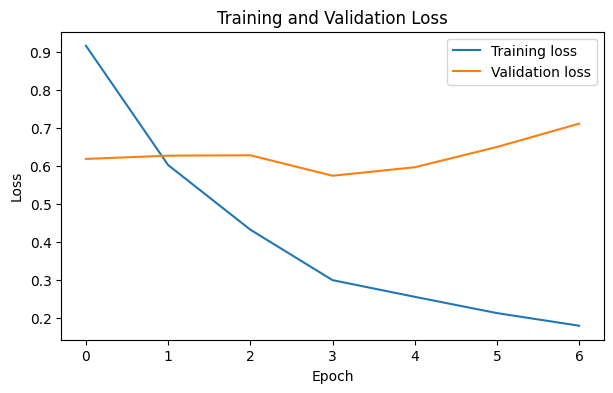

In [26]:
history_df = pd.DataFrame(history.history)

plt.figure(figsize=(7, 4))
plt.plot(history_df["loss"], label="Training loss")
plt.plot(history_df["val_loss"], label="Validation loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

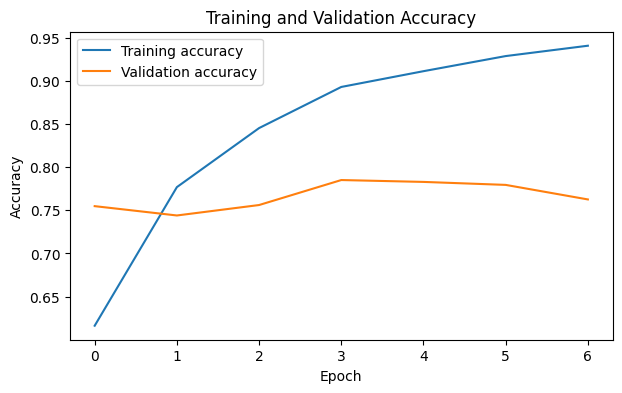

In [27]:
plt.figure(figsize=(7, 4))
plt.plot(history_df["accuracy"], label="Training accuracy")
plt.plot(history_df["val_accuracy"], label="Validation accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

## 11. Validation Results

In [28]:
val_probs = model.predict(X_val_pad, verbose=0)
val_preds = np.argmax(val_probs, axis=1)

print("Validation Macro F1:", round(f1_score(y_val_enc, val_preds, average="macro"), 4))
print(classification_report(
    y_val_enc, val_preds,
    labels=[0, 1, 2],
    target_names=label_order,
    zero_division=0
))

Validation Macro F1: 0.7279
              precision    recall  f1-score   support

    negative       0.87      0.86      0.86      1454
     neutral       0.62      0.62      0.62       491
    positive       0.67      0.73      0.70       368

    accuracy                           0.79      2313
   macro avg       0.72      0.73      0.73      2313
weighted avg       0.79      0.79      0.79      2313



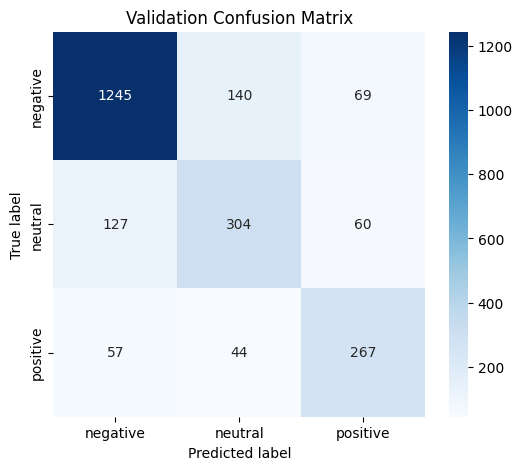

In [29]:
cm_val = confusion_matrix(y_val_enc, val_preds, labels=[0, 1, 2])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_val, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_order, yticklabels=label_order)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Validation Confusion Matrix")
plt.show()

## 12. Final Evaluation on the Held-Out Test Set

In [30]:
test_probs = model.predict(X_test_pad, verbose=0)
test_preds = np.argmax(test_probs, axis=1)

final_macro_f1 = f1_score(y_test_enc, test_preds, average="macro")
print(f"Final Test Macro F1: {final_macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test_enc,
    test_preds,
    labels=[0, 1, 2],
    target_names=label_order,
    zero_division=0
))

Final Test Macro F1: 0.7351

Classification Report:
              precision    recall  f1-score   support

    negative       0.87      0.86      0.86      1818
     neutral       0.63      0.62      0.62       613
    positive       0.70      0.74      0.72       460

    accuracy                           0.79      2891
   macro avg       0.73      0.74      0.74      2891
weighted avg       0.79      0.79      0.79      2891



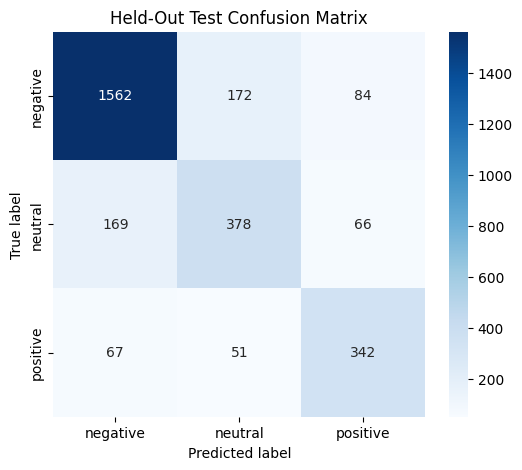

In [33]:
cm_test = confusion_matrix(y_test_enc, test_preds, labels=[0, 1, 2])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_order, yticklabels=label_order)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Held-Out Test Confusion Matrix")
plt.show()

## 13. Save the Model and Tokenizer

In [34]:
model.save("Twitter_Airline_BiLSTM.keras")

import pickle
with open("twitter_airline_tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

with open("twitter_airline_label_mapping.pkl", "wb") as f:
    pickle.dump({"label_to_id": label_to_id, "id_to_label": id_to_label}, f)

print("Model, tokenizer, and label mapping saved.")

Model, tokenizer, and label mapping saved.
